In [1]:
# Z-score assumes that the data is normally distributed
# 1 sigma, 68% data lies
# 2 sigma, 95% data lies 

In [4]:
# Ways to remove outliers
    #Trimming--> data nai hataidiney
    #Capping--> minimum vaye -3 sigma navaye maximum vaye 3 sigma

In [2]:
import numpy as np
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt

In [6]:
df = pd.read_csv('placement.csv')

In [7]:
df.head(2)

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1


In [8]:
df.shape

(1000, 3)

C:\Users\dell\AppData\Local\Temp\ipykernel_18852\1773263812.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['cgpa'], kde=True)


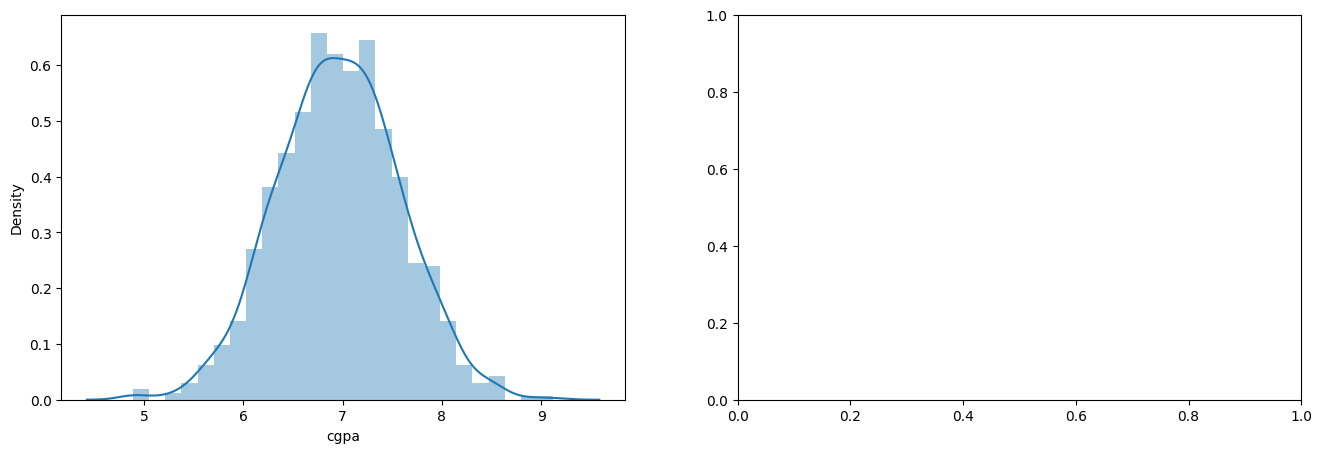

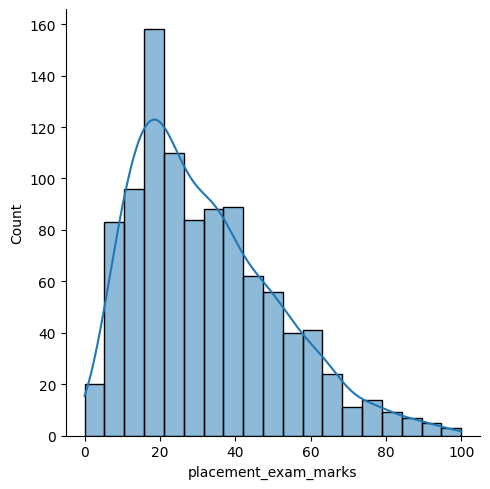

In [10]:
plt.figure(figsize=(16,5))
plt.subplot(1,2,1)
sns.distplot(df['cgpa'], kde=True)
plt.subplot(1,2,2)
sns.displot(df['placement_exam_marks'], kde=True)
plt.show()

In [15]:
mean=df['cgpa'].mean()
mean

6.96124

In [16]:
std=df['cgpa'].std()
std

0.6158978751323894

In [17]:
min=df['cgpa'].min()
min

4.89

In [18]:
max=df['cgpa'].max()
max

9.12

In [19]:
print("Max allowed due to Z-score", mean+3*std)
print("Min allowed due to Z-score", mean-3*std)

Max allowed due to Z-score 8.808933625397168
Min allowed due to Z-score 5.113546374602832


In [25]:
df[(df['cgpa']>8.80)| (df['cgpa']<5.11)]

,cgpa,placement_exam_marks,placed
485,4.92,44.0,1
995,8.87,44.0,1
996,9.12,65.0,1
997,4.89,34.0,0
999,4.90,10.0,1


In [26]:
new_df=df[(df['cgpa']<8.80)| (df['cgpa']>5.11)]

In [27]:
new_df.sample(4)

,cgpa,placement_exam_marks,placed
36,6.85,16.0,1
122,5.97,51.0,0
544,7.11,14.0,1
535,6.49,62.0,0


In [28]:
new_df['Z_score'] = (new_df['cgpa']-mean)/std

In [29]:
new_df.sample(4)

,cgpa,placement_exam_marks,placed,Z_score
609,6.55,4.0,0,-0.667708
844,7.62,18.0,1,1.069593
340,7.45,51.0,0,0.793573
243,6.78,55.0,0,-0.294270


## Capping

In [30]:
upper_limit=mean+3*std

In [31]:
lower_limit=mean-3*std

In [33]:
df['cgpa']=np.where(df['cgpa']>upper_limit, upper_limit, df['cgpa'])

In [34]:
df.head(3)

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1


In [35]:
df['cgpa']=np.where(df['cgpa']<lower_limit, lower_limit, df['cgpa'])

In [39]:
df[(df['cgpa']>upper_limit)| (df['cgpa']<lower_limit)]

,cgpa,placement_exam_marks,placed
